<a href="https://colab.research.google.com/github/jatinkumar-creator/machine-learning-portfolio/blob/main/01_Data_Preprocessing/notebooks/04_Feature_Engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Create the dataset
import pandas as pd
import numpy as np

data = {
    "Customer": ["Rahul", "Priya", "Amit", "Neha", "Karan"],
    "Total_Purchases": [10, 20, 5, 15, 8],
    "Total_Spending": [20000, 50000, 10000, 45000, 16000],
    "Age": [25, 30, 35, 28, 40]
}

df = pd.DataFrame(data)

display(df)

,Customer,Total_Purchases,Total_Spending,Age
0,Rahul,10,20000,25
1,Priya,20,50000,30
2,Amit,5,10000,35
3,Neha,15,45000,28
4,Karan,8,16000,40


In [2]:
#Create a new feature
df["Average_Purchase"] = (
    df["Total_Spending"] / df["Total_Purchases"]
)

display(df)

,Customer,Total_Purchases,Total_Spending,Age,Average_Purchase
0,Rahul,10,20000,25,2000.0
1,Priya,20,50000,30,2500.0
2,Amit,5,10000,35,2000.0
3,Neha,15,45000,28,3000.0
4,Karan,8,16000,40,2000.0


In [3]:
#Create spending categories
def spending_category(amount):

    if amount < 20000:
        return "Low"

    elif amount < 40000:
        return "Medium"

    else:
        return "High"


df["Spending_Category"] = df["Total_Spending"].apply(
    spending_category
)

display(df)

,Customer,Total_Purchases,Total_Spending,Age,Average_Purchase,Spending_Category
0,Rahul,10,20000,25,2000.0,Medium
1,Priya,20,50000,30,2500.0,High
2,Amit,5,10000,35,2000.0,Low
3,Neha,15,45000,28,3000.0,High
4,Karan,8,16000,40,2000.0,Low


In [4]:
#Apply log transformation
df["Log_Spending"] = np.log1p(df["Total_Spending"])

display(df)

,Customer,Total_Purchases,Total_Spending,Age,Average_Purchase,Spending_Category,Log_Spending
0,Rahul,10,20000,25,2000.0,Medium,9.903538
1,Priya,20,50000,30,2500.0,High,10.819798
2,Amit,5,10000,35,2000.0,Low,9.210440
3,Neha,15,45000,28,3000.0,High,10.714440
4,Karan,8,16000,40,2000.0,Low,9.680406


In [5]:
#Inspect the final dataset
print("Final dataset shape:", df.shape)

print("\nFinal columns:")

print(df.columns.tolist())

Final dataset shape: (5, 7)

Final columns:
['Customer', 'Total_Purchases', 'Total_Spending', 'Age', 'Average_Purchase', 'Spending_Category', 'Log_Spending']


Now we have three new features:
1. Average_Purchase
2. Spending_Category
3. Log_Spending

Correlation
Before selecting features, it can be useful to examine relationships between numerical variables.

Correlation measures the strength and direction of a linear relationship between two numerical variables.

Its value ranges from -1 to +1.
Correlation	Meaning
+1	Perfect positive linear relationship
0	No linear relationship
-1	Perfect negative linear relationship

For example:
- As advertising spending increases, sales may increase.
- As product price increases, demand may decrease.

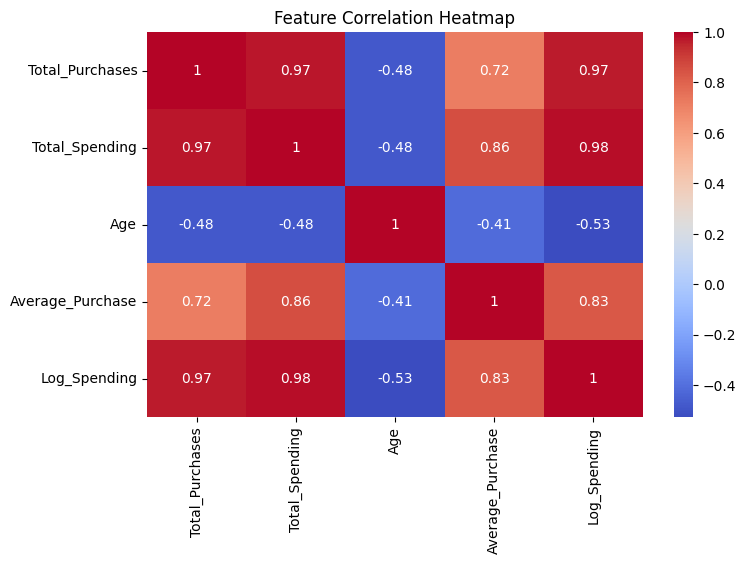

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Feature Correlation Heatmap")

plt.show()